# simulate_EColi
Python version of the example of `simulate_EColi` (`R/sybilccFBA/man/simulate_EColi.Rd`): growth of *E. coli*
iML1515 on 24 carbon sources with ccFBA (`getccFBA_mat`), kcat values `allKcats_upd34_dd_h.csv` (kcat_max) and
protein complex stoichiometry (`cpx_stoich_me.csv`), budget C = 0.27, transport reactions of the outer membrane
(`tex`) excluded from the budget.

The model and the molecular weights are the data sets of the R package (`.RData`), read with `sybil2cobra.read_RData`
(needs `pip install rdata`); the ids are kept as in sybil (e.g. `EX_glc__D(e)`).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

from sybil2cobra import read_RData
from getccFBA_mat import mod2irrev
from simulate_EColi import simulate_EColi

pkg = os.path.join('R', 'sybilccFBA')

### 1- get metabolic model

In [2]:
model = read_RData(os.path.join(pkg, 'data', 'iML1515.RData'))['iML1515']
print(model.id, len(model.reactions), 'reactions', len(model.metabolites), 'metabolites', len(model.genes), 'genes')

iML1515 2712 reactions 1877 metabolites 1516 genes


### 2- get molecular weights
The spontaneous 'gene' `s0001` gets a very small molecular weight, as in R.

In [3]:
mw = read_RData(os.path.join(pkg, 'data', 'mw_iML1515.RData'))['mw_iML1515']
mw = pd.concat([mw, pd.DataFrame({'Synonym': ['s0001'], 'mw': [0.001]})], ignore_index=True)
mw.columns = ['gene'] + list(mw.columns[1:])
mw.tail(3)

,gene,mw
1513,b0349,31.937356
1514,b4104,22.797000
1515,s0001,0.001000


### 3- get kcat list

In [4]:
kl = pd.read_csv(os.path.join(pkg, 'inst', 'extdata', 'allKcats_upd34_dd_h.csv'))
kl = kl[kl['ijo_id'].notna()]
kcat = pd.DataFrame({'rxn_id': kl['ijo_id'], 'val': kl['kcat_max'], 'dirxn': kl['dirxn'], 'src': kl['src']})
kcat = kcat[kcat['rxn_id'].isin([r.id for r in model.reactions])]
kcat.loc[kcat['src'].isna(), 'src'] = 'Max'
print(kcat.shape)
kcat['src'].value_counts()

(651, 4)


src
All organisms    251
E. coli          231
Max              163
Valg               4
BRENDA             1
Salmonila          1
Name: count, dtype: int64

### 4- get complex stoichiometry if used

In [5]:
cpx_stoich = pd.read_csv(os.path.join(pkg, 'inst', 'extdata', 'cpx_stoich_me.csv'))
cpx_stoich[['genes', 'stoich']].head()

,genes,stoich
0,b3018,1
1,b2168,2
2,b0425,1
3,b0074,1
4,b3833,1


### 5- identify carbon sources to be tested
Uptake reactions (backward direction `_b` of the exchange reactions), measured growth rates and number of carbon atoms.

In [6]:
csl = ["EX_glc__D(e)_b", "EX_glyc(e)_b", "EX_ac(e)_b", "EX_fru(e)_b", "EX_pyr(e)_b", "EX_gal(e)_b",
       "EX_lac__L(e)_b", "EX_malt(e)_b", "EX_mal__L(e)_b", "EX_fum(e)_b", "EX_xyl__D(e)_b", "EX_man(e)_b", "EX_tre(e)_b",
       "EX_mnl(e)_b", "EX_g6p(e)_b", "EX_succ(e)_b", "EX_gam(e)_b", "EX_sbt__D(e)_b", "EX_glcn(e)_b",
       "EX_rib__D(e)_b", "EX_gsn(e)_b", "EX_ala__L(e)_b", "EX_akg(e)_b", "EX_acgam(e)_b"]

msrd = [0.66,0.47,0.29,0.54,0.41,0.24,0.41,0.52,0.55,0.47,0.51,0.35,0.48,0.61,
        0.78,0.50,0.40,0.48,0.68,0.41,0.37,0.24,0.24,0.61]
CA = [6,3,2,6,3,6,3,12,4,4,5,6,12,6,6,4,6,6,6,5,10,3,5,8]

### 6- get irreversible model
In R `react_rev(model1)` is set to `TRUE` for the exchange reactions of the carbon sources before `mod2irrev`; in
python they are given in `rev`, so that they are split in `_f` and `_b`. Then the uptake and the secretion of all carbon
sources is closed, and the oxygen uptake is opened.

In [7]:
cs_rxns = [c[:-2] for c in csl]   # gsub('_b$', '', csl)
print(sum(r.id in cs_rxns for r in model.reactions))
mod2 = mod2irrev(model, rev=cs_rxns)
print(mod2)

print([mod2.react_name[mod2.react_id.index(c)] for c in csl])

for c in csl:
    mod2.uppbnd[mod2.react_id.index(c)] = 0
    mod2.uppbnd[mod2.react_id.index(c[:-2] + '_f')] = 0
mod2.uppbnd[mod2.react_id.index('EX_o2(e)_b')] = 1000
trns_rxns = [r.id.endswith('tex') for r in model.reactions]   # grepl("tex$", react_id(model))
print('tex reactions:', sum(trns_rxns))

24


<IrrevModel iML1515: 3398 reactions (686 split), 1877 metabolites>
['D-Glucose exchange', 'Glycerol exchange', 'Acetate exchange', 'D-Fructose exchange', 'Pyruvate exchange', 'D-Galactose exchange', 'L-Lactate exchange', 'Maltose exchange', 'L-Malate exchange', 'Fumarate exchange', 'D-Xylose exchange', 'D-Mannose exchange', 'Trehalose exchange', 'D-Mannitol exchange', 'D-Glucose 6-phosphate exchange', 'Succinate exchange', 'D-Glucosamine exchange', 'D-Sorbitol exchange', 'D-Gluconate exchange', 'D-Ribose exchange', 'Guanosine exchange', 'L-Alanine exchange', '2-Oxoglutarate exchange', 'N-Acetyl-D-glucosamine exchange']
tex reactions: 311


### Call function

In [8]:
tmp_res = simulate_EColi(model, mod2, mw=mw, budget_C=0.27, kcat=kcat, cpx_stoich=cpx_stoich,
                         atpmz=False, trns_rxns=trns_rxns, CSList=csl)

excluded transport reactions:311
Preprocessing isoenzymes ... 


Preparing LP ... 


Enzyme variables: {'gr': 1097, 'g1': 576, 'cp': 288}
Adding constraints for mapping AND to min
Adding multiple reactions constraints
Adding capacity constraint.


LP: 5558 rows, 6743 columns (1246 genes, 1811 multi-functional parts, 288 complexes)
1 EX_glc__D(e)_b


optimal
2 EX_glyc(e)_b


optimal
3 EX_ac(e)_b


... (18 outputs left out)

optimal
22 EX_ala__L(e)_b


optimal
23 EX_akg(e)_b


optimal
24 EX_acgam(e)_b


optimal


In [9]:
bm = tmp_res['gr_data']
print(spearmanr(bm['flx'], msrd))   # cor.test(bm[,'flx'], msrd, method='spearman')

SignificanceResult(statistic=np.float64(0.37481040344194183), pvalue=np.float64(0.07113652515383198))


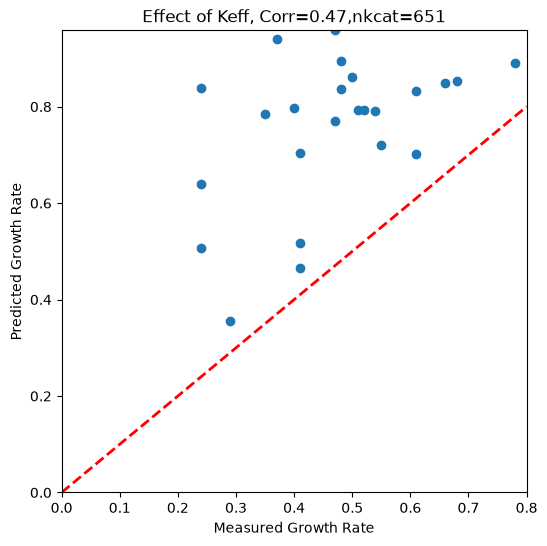

In [10]:
corr = pearsonr(bm['flx'], msrd)[0]   # cor(bm[,'flx'], msrd)
plt.figure(figsize=(6, 6))
plt.scatter(msrd, bm['flx'])
plt.xlim(0, 0.8)
plt.ylim(0, max(bm['flx']))
plt.xlabel('Measured Growth Rate')
plt.ylabel('Predicted Growth Rate')
plt.title('Effect of Keff, Corr=%.2f,nkcat=%d' % (corr, len(kcat)))
plt.axline((0, 0), slope=1, color='red', lw=2, ls='--')   # abline(a=0, b=1)
plt.show()

### Results
Predicted growth rate and uptake of each carbon source (mmol/gDW/h; C_uptake = uptake × number of carbon atoms).

In [11]:
res = pd.DataFrame({'carbon_source': csl, 'measured_growth': msrd, 'predicted_growth': bm['flx'].values,
                    'uptake': tmp_res['uptake']['flx'].values, 'C_atoms': CA})
res['C_uptake'] = res['uptake'] * res['C_atoms']
res

,carbon_source,measured_growth,predicted_growth,uptake,C_atoms,C_uptake
0,EX_glc__D(e)_b,0.66,0.849555,10.523068,6,63.138406
1,EX_glyc(e)_b,0.47,0.957910,36.217569,3,108.652706
2,EX_ac(e)_b,0.29,0.355223,18.823630,2,37.647260
3,EX_fru(e)_b,0.54,0.791099,9.911126,6,59.466754
4,EX_pyr(e)_b,0.41,0.466092,19.342462,3,58.027386
5,EX_gal(e)_b,0.24,0.837980,10.376665,6,62.259989
6,EX_lac__L(e)_b,0.41,0.517838,18.193373,3,54.580118
7,EX_malt(e)_b,0.52,0.793991,4.978911,12,59.746936
8,EX_mal__L(e)_b,0.55,0.720875,69.410739,4,277.642957
9,EX_fum(e)_b,0.47,0.770958,52.752582,4,211.010329


Reactions with the largest protein cost (molecular crowding, `rxnMC` in g/gDW) on glucose:

In [12]:
rg = tmp_res['rg_MC']
rg[rg['cs'] == 1].head(10)[['rxnMCorder', 'rxn_id', 'gene', 'gpr.genes', 'flx', 'kcat', 'enzConc', 'rxnMC', 'rgMC']]

,rxnMCorder,rxn_id,gene,gpr.genes,flx,kcat,enzConc,rxnMC,rgMC
0,1,GLNS,b3870,b3870,1.330791,21600.0,0.000062,0.038374,0.038374
1,2,ATPS4rpp_f,b3734,"b3731,b3732,b3733,b3734,b3735,b3736,b3737,b373...",86.130333,972000.0,0.000089,0.021354,0.004893
2,3,ATPS4rpp_b,b3734,"b3731,b3732,b3733,b3734,b3735,b3736,b3737,b373...",0.000000,781200.0,0.000089,0.021354,0.004893
3,4,ATPS4rpp_f,b3732,"b3731,b3732,b3733,b3734,b3735,b3736,b3737,b373...",86.130333,972000.0,0.000089,0.021354,0.004459
4,5,ATPS4rpp_b,b3732,"b3731,b3732,b3733,b3734,b3735,b3736,b3737,b373...",0.000000,781200.0,0.000089,0.021354,0.004459
5,6,ATPS4rpp_f,b3733,"b3731,b3732,b3733,b3734,b3735,b3736,b3737,b373...",86.130333,972000.0,0.000089,0.021354,0.002798
6,7,ATPS4rpp_b,b3733,"b3731,b3732,b3733,b3734,b3735,b3736,b3737,b373...",0.000000,781200.0,0.000089,0.021354,0.002798
7,8,ATPS4rpp_f,b3738,"b3731,b3732,b3733,b3734,b3735,b3736,b3737,b373...",86.130333,972000.0,0.000089,0.021354,0.002685
8,9,ATPS4rpp_b,b3738,"b3731,b3732,b3733,b3734,b3735,b3736,b3737,b373...",0.000000,781200.0,0.000089,0.021354,0.002685
9,10,ATPS4rpp_f,b3735,"b3731,b3732,b3733,b3734,b3735,b3736,b3737,b373...",86.130333,972000.0,0.000089,0.021354,0.001713


## Proteins consuming the budget (glucose)
Protein cost of each gene: `gMC = gMW * geneConc` (g protein/gDW), with `geneConc` the total concentration of the gene
(for a multi-functional enzyme the sum of its parts used by the different reactions), so each protein is counted once.
`pct_budget` is the percentage of the budget C used by the protein. Gene names and products are from
`iJO1366_genedef.csv` of the R package (not available for all iML1515 genes). `used_by`: reactions (directions) that
carry flux and use the protein.

In [13]:
budget_C = 0.27
cs_name = 'EX_glc__D(e)_b'   # glucose

fm = tmp_res['all_flx_MC']
fm = fm[fm['csname'] == cs_name]
# one row per gene that has a concentration variable (genes of the reactions in the budget)
gMC = (fm[fm['gCol'].notna()].drop_duplicates('gene')
       [['gene', 'gMW', 'geneConc', 'genercnt']].rename(columns={'genercnt': 'n_rxns'}))
gMC['gMC'] = gMC['gMW'].fillna(0) * gMC['geneConc']
gMC['pct_budget'] = 100 * gMC['gMC'] / budget_C
# reactions that carry flux and use the gene
used = fm[(fm['grConc'] > 1e-12) & (fm['flx'] > 1e-9)].groupby('gene')['rxn_id'].apply(lambda r: ', '.join(sorted(set(r))))
gMC['used_by'] = gMC['gene'].map(used).fillna('')
genedef = pd.read_csv(os.path.join(pkg, 'inst', 'extdata', 'iJO1366_genedef.csv'))[['gene', 'gname', 'PRODUCT']]
gMC = gMC.merge(genedef, on='gene', how='left').sort_values('gMC', ascending=False, ignore_index=True)

tol = 1e-9   # smaller values are numerical noise of the solver
print('genes: %d, used (gMC > %g): %d, total gMC: %.4f g/gDW (%.1f%% of the budget)'
      % (len(gMC), tol, (gMC['gMC'] > tol).sum(), gMC['gMC'].sum(), gMC['pct_budget'].sum()))
top10 = gMC.head(10)[['gene', 'gname', 'PRODUCT', 'gMW', 'geneConc', 'gMC', 'pct_budget', 'n_rxns', 'used_by']]
print('top 10 proteins use %.1f%% of the budget' % top10['pct_budget'].sum())
top10

genes: 1246, used (gMC > 1e-09): 329, total gMC: 0.2700 g/gDW (100.0% of the budget)
top 10 proteins use 52.2% of the budget


,gene,gname,PRODUCT,gMW,geneConc,gMC,pct_budget,n_rxns,used_by
0,b3870,glnA,glutamine synthetase,51.903578,0.000739,0.038374,14.212515,1,GLNS
1,b3774,ilvC,"ketol-acid reductoisomerase, NAD(P)-binding",54.068861,0.000373,0.020192,7.478575,2,"KARA1_b, KARA2_f"
2,b2029,gnd,"6-phosphogluconate dehydrogenase, decarboxylating",51.481058,0.000386,0.019882,7.363788,1,GND
3,b2465,tktB,"transketolase 2, thiamin-binding",73.042408,0.000232,0.016930,6.270394,2,"TKT1_f, TKT2_f"
4,b4139,aspA,aspartate ammonia-lyase,52.355986,0.000262,0.013705,5.075801,1,ASPT
5,b0118,acnB,bifunctional aconitate hydratase 2/2-methyliso...,93.497765,0.000107,0.010011,3.707885,3,"ACONTa_f, ACONTb_f"
6,b0907,serC,3-phosphoserine/phosphohydroxythreonine aminot...,39.783160,0.000158,0.006283,2.327058,2,"OHPBAT_f, PSERT"
7,b2943,galP,D-galactose transporter,50.982336,0.000110,0.005624,2.082811,2,GLCt2pp
8,b4122,fumB,anaerobic class I fumarate hydratase (fumarase B),60.105089,0.000083,0.004984,1.845825,2,FUM_f
9,b3734,atpA,"F1 sector of membrane-bound ATP synthase, alph...",55.221850,0.000089,0.004893,1.812329,1,ATPS4rpp_f


Histogram of gMC of the proteins used on glucose (gMC > tol; the other genes are not used). The distribution is very
skewed, so the right panel uses logarithmic bins; the red line marks the 10th protein.

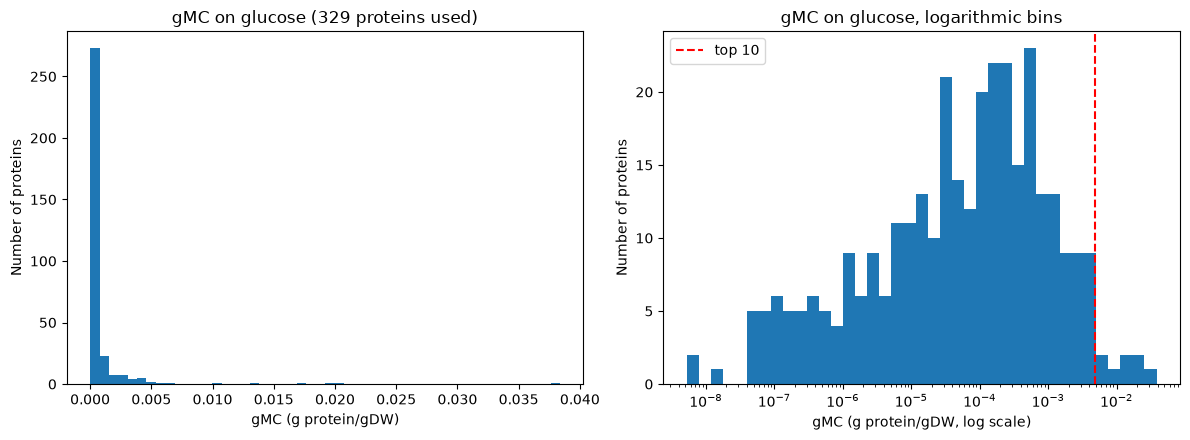

In [14]:
import numpy as np

pos = gMC.loc[gMC['gMC'] > tol, 'gMC']
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(pos, bins=50)
ax[0].set_xlabel('gMC (g protein/gDW)')
ax[0].set_ylabel('Number of proteins')
ax[0].set_title('gMC on glucose (%d proteins used)' % len(pos))
ax[1].hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 40))
ax[1].set_xscale('log')
ax[1].axvline(gMC['gMC'].iloc[9], color='red', ls='--', label='top 10')
ax[1].set_xlabel('gMC (g protein/gDW, log scale)')
ax[1].set_ylabel('Number of proteins')
ax[1].set_title('gMC on glucose, logarithmic bins')
ax[1].legend()
plt.tight_layout()
plt.show()